# Part 1: Baseline Model

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, average_precision_score, confusion_matrix)

pd.set_option('display.max_columns', None)

In [7]:
DATA_PATH = '../data/fraud_oracle.csv'
df = pd.read_csv(DATA_PATH, encoding='utf-8-sig')
print('Original rows and columns:', df.shape)

broken_row = (df['MonthClaimed'].astype(str).str.strip() == '0') | (df['DayOfWeekClaimed'].astype(str).str.strip() == '0')
print('Rows to remove:', broken_row.sum())
display(df.loc[broken_row, ['PolicyNumber', 'MonthClaimed', 'DayOfWeekClaimed', 'Age']])
assert broken_row.sum() == 1, 'Check the dictionary before removing a different number of rows.'
assert df.loc[broken_row, 'PolicyNumber'].tolist() == [1517]
df = df.loc[~broken_row].copy()

print('Rows after cleaning:', len(df))
print('Remaining zero ages:', (df['Age'] == 0).sum())
print('Duplicate rows:', df.duplicated().sum())


Original rows and columns: (15420, 33)
Rows to remove: 1


,PolicyNumber,MonthClaimed,DayOfWeekClaimed,Age
1516,1517,0,0,0


Rows after cleaning: 15419
Remaining zero ages: 319
Duplicate rows: 0


# Feature audit and final working decisions

In [8]:
drop_reasons = {
    'PolicyNumber': 'An identifier that follows row order and year.',
    'RepNumber': 'An employee identifier; excluded by team decision.',
    'PolicyType': 'Overlaps BasePolicy and conflicts with VehicleCategory in some rows.',
    'PoliceReportFiled': 'Likely recorded during claim processing.',
    'WitnessPresent': 'Witness information may be established during investigation.',
    'NumberOfSuppliments': 'Additional claim amounts or amendments may be added later.',
    'AddressChange_Claim': 'Recording time is unclear; excluded by team decision.',
    'Year': 'Used to split claims, not as a predictor.'
}
display(pd.DataFrame(drop_reasons.items(), columns=['Column to drop', 'Reason']))
kept_columns = [column for column in df.columns
                if column not in drop_reasons and column != 'FraudFound_P']
print('Columns kept:', kept_columns)
print('Original input count:', len(kept_columns))
display(pd.DataFrame({
    'Column': ['Fault', 'AgeOfPolicyHolder', 'Sex'],
    'Note': ['Kept but flagged: timing at first filing remains uncertain.',
             'Kept as a bucket; youngest bucket overlaps missing Age.',
             'Kept per dictionary; subgroup fairness needs review before deployment.']
}))
assert 'Fault' in kept_columns and 'AgeOfPolicyHolder' in kept_columns
assert 'PolicyType' not in kept_columns


,Column to drop,Reason
0,PolicyNumber,An identifier that follows row order and year.
1,RepNumber,An employee identifier; excluded by team decis...
2,PolicyType,Overlaps BasePolicy and conflicts with Vehicle...
3,PoliceReportFiled,Likely recorded during claim processing.
4,WitnessPresent,Witness information may be established during ...
5,NumberOfSuppliments,Additional claim amounts or amendments may be ...
6,AddressChange_Claim,Recording time is unclear; excluded by team de...
7,Year,"Used to split claims, not as a predictor."


Columns kept: ['Month', 'WeekOfMonth', 'DayOfWeek', 'Make', 'AccidentArea', 'DayOfWeekClaimed', 'MonthClaimed', 'WeekOfMonthClaimed', 'Sex', 'MaritalStatus', 'Age', 'Fault', 'VehicleCategory', 'VehiclePrice', 'Deductible', 'DriverRating', 'Days_Policy_Accident', 'Days_Policy_Claim', 'PastNumberOfClaims', 'AgeOfVehicle', 'AgeOfPolicyHolder', 'AgentType', 'NumberOfCars', 'BasePolicy']
Original input count: 24


,Column,Note
0,Fault,Kept but flagged: timing at first filing remai...
1,AgeOfPolicyHolder,Kept as a bucket; youngest bucket overlaps mis...
2,Sex,Kept per dictionary; subgroup fairness needs r...


# Create one training/hold-out split

In [9]:
train_df = df[df['Year'] == 1994].copy()
val_df = df[df['Year'] == 1995].copy()
test_df = df[df['Year'] == 1996].copy()  

assert set(train_df.index).isdisjoint(val_df.index)
assert set(train_df.index).isdisjoint(test_df.index)
assert set(val_df.index).isdisjoint(test_df.index)
assert len(train_df) + len(val_df) + len(test_df) == len(df)

display(pd.DataFrame({
    'Split': ['Training: 1994', 'Validation: 1995'],
    'Claims': [len(train_df), len(val_df)],
    'Fraud cases': [train_df['FraudFound_P'].sum(), val_df['FraudFound_P'].sum()],
    'Fraud rate': [train_df['FraudFound_P'].mean(), val_df['FraudFound_P'].mean()]
}))
print('Reserved 1996 rows:', len(test_df))


,Split,Claims,Fraud cases,Fraud rate
0,Training: 1994,6141,409,0.066602
1,Validation: 1995,5195,301,0.057940


Reserved 1996 rows: 4083


# Clean missing ages using the training median

In [10]:
for data in [train_df, val_df]:
    data['AgeMissing'] = ((data['Age'] == 0) | data['Age'].isna()).astype(int)
    data['Age'] = data['Age'].replace(0, np.nan)

training_median = train_df['Age'].median()
train_df['Age'] = train_df['Age'].fillna(training_median)
val_df['Age'] = val_df['Age'].fillna(training_median)
print('1994 age median:', training_median)
print('Training ages originally missing:', train_df['AgeMissing'].sum())

input_columns = kept_columns + ['AgeMissing']
X_train = train_df[input_columns].copy()
y_train = train_df['FraudFound_P'].copy()
X_val = val_df[input_columns].copy()
y_val = val_df['FraudFound_P'].copy()



1994 age median: 38.0
Training ages originally missing: 154


# Group rare vehicle makes
Added from the dictionary: makes with fewer than 50 training claims become Other. This is a simple starting rule chosen before comparison, not a threshold tuned on validation results. Learn the common makes from 1994 only. Reuse the same list for 1995, including any make not seen in training. This reduces the number of very small categories.

In [11]:
make_counts = X_train['Make'].value_counts()
common_makes = make_counts[make_counts >= 50].index
rare_makes = make_counts[make_counts < 50]
display(rare_makes.to_frame('1994 claims grouped as Other'))
X_train['Make'] = X_train['Make'].where(X_train['Make'].isin(common_makes), 'Other')
X_val['Make'] = X_val['Make'].where(X_val['Make'].isin(common_makes), 'Other')



,1994 claims grouped as Other
Make,
Saab,48
Dodge,41
Mercury,36
Saturn,22
Nisson,12
Jaguar,4
BMW,4
Porche,2
Mecedes,2


# Turn ordered ranges into simple numbers
Added from the dictionary's encoding decisions.

AgeOfPolicyHolder = '16 to 17' keeps its bucket code as requested, but is not used to fill Age. Its overlap with AgeMissing is noted in the audit.

In [12]:
range_codes = {
    'VehiclePrice': {'less than 20000': 1, '20000 to 29000': 2,
                     '30000 to 39000': 3, '40000 to 59000': 4,
                     '60000 to 69000': 5, 'more than 69000': 6},
    'Days_Policy_Accident': {'none': 0, '1 to 7': 1, '8 to 15': 2,
                           '15 to 30': 3, 'more than 30': 4},
    'Days_Policy_Claim': {'none': 0, '8 to 15': 1, '15 to 30': 2, 'more than 30': 3},
    'PastNumberOfClaims': {'none': 0, '1': 1, '2 to 4': 2, 'more than 4': 3},
    'AgeOfVehicle': {'new': 0, '2 years': 1, '3 years': 2, '4 years': 3,
                     '5 years': 4, '6 years': 5, '7 years': 6, 'more than 7': 7},
    'AgeOfPolicyHolder': {'16 to 17': 1, '18 to 20': 2, '21 to 25': 3,
                         '26 to 30': 4, '31 to 35': 5, '36 to 40': 6,
                         '41 to 50': 7, '51 to 65': 8, 'over 65': 9},
    'NumberOfCars': {'1 vehicle': 1, '2 vehicles': 2, '3 to 4': 3,
                     '5 to 8': 4, 'more than 8': 5}
}
for column, mapping in range_codes.items():
    X_train[column] = X_train[column].map(mapping)
    X_val[column] = X_val[column].map(mapping)
    assert X_train[column].notna().all(), 'Unrecognized training category: ' + column
    assert X_val[column].notna().all(), 'Unrecognized validation category: ' + column

display(X_train[list(range_codes)].head())


,VehiclePrice,Days_Policy_Accident,Days_Policy_Claim,PastNumberOfClaims,AgeOfVehicle,AgeOfPolicyHolder,NumberOfCars
0,6,4,3,0,2,4,3
1,6,4,3,0,5,5,1
2,6,4,3,1,6,7,1
3,2,4,3,1,7,8,1
4,6,4,3,0,4,5,1


# Encode the remaining categories and scale the numbers
The fitted encoder columns and scaler come from 1994. A category that appears only in 1995 does not create a new training feature.

In [13]:
category_columns = X_train.select_dtypes(include=['object', 'string', 'category']).columns.tolist()
category_columns += ['WeekOfMonth', 'WeekOfMonthClaimed', 'DriverRating']
category_columns = list(dict.fromkeys(category_columns))

X_train_encoded = pd.get_dummies(X_train, columns=category_columns, dtype=int)
X_val_encoded = pd.get_dummies(X_val, columns=category_columns, dtype=int)
X_val_encoded = X_val_encoded.reindex(columns=X_train_encoded.columns, fill_value=0)

numeric_columns = ['Age', 'Deductible'] + list(range_codes)
scaler = StandardScaler()
X_train_ready = X_train_encoded.copy()
X_val_ready = X_val_encoded.copy()
X_train_ready[numeric_columns] = scaler.fit_transform(X_train_encoded[numeric_columns])
X_val_ready[numeric_columns] = scaler.transform(X_val_encoded[numeric_columns])

assert X_train_ready.columns.equals(X_val_ready.columns)
assert not X_train_ready.isna().any().any()
assert not X_val_ready.isna().any().any()
print('Training shape:', X_train_ready.shape)
print('Validation shape:', X_val_ready.shape)


Training shape: (6141, 89)
Validation shape: (5195, 89)


# Train the logistic regression baseline
Predict scores for 1995 only.

In [14]:
model = LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)
model.fit(X_train_ready, y_train)
val_probabilities = model.predict_proba(X_val_ready)[:, 1]


# Build the coverage + fault lookup rule
Calculate fraud rates for each BasePolicy and Fault group using 1994 labels only. Assign each 1995 claim the rate of its group.

This is a simple comparison rule, not another machine learning model. If a validation group is missing from training, use the overall training fraud rate. Group counts are shown so a rate based on a small group is not mistaken for a reliable estimate.

In [57]:
group_rates = train_df.groupby(['BasePolicy', 'Fault'])['FraudFound_P'].agg(
    Claims='size', Fraud_cases='sum', Fraud_rate='mean'
).reset_index()
display(group_rates)

# left merge keeps every validation claim in its original order.
lookup_input = val_df[['BasePolicy', 'Fault']].reset_index(drop=True)
lookup_input['row_order'] = np.arange(len(lookup_input))
lookup_predictions = lookup_input.merge(
    group_rates[['BasePolicy', 'Fault', 'Fraud_rate']],
    on=['BasePolicy', 'Fault'], how='left', validate='many_to_one'
).sort_values('row_order')
lookup_scores = lookup_predictions['Fraud_rate'].fillna(y_train.mean()).to_numpy()
assert len(lookup_scores) == len(y_val)


,BasePolicy,Fault,Claims,Fraud_cases,Fraud_rate
0,All Perils,Policy Holder,1161,226,0.194660
1,All Perils,Third Party,653,5,0.007657
2,Collision,Policy Holder,1681,152,0.090422
3,Collision,Third Party,712,11,0.015449
4,Liability,Policy Holder,1665,14,0.008408
5,Liability,Third Party,269,1,0.003717


# Compare the four approaches at the same review capacity
Added: one 1995 results table with AP, fraud captured at 10% and 20%, and precision among the top 20%.
- AP (PR-AUC summary): higher means better ranking of fraud. This is average precision, not trapezoidal area. Constant-score AP equals validation prevalence.
- Fraud captured: fraud found in the reviewed claims divided by all actual fraud.
- Precision among reviewed: actual fraud divided by claims reviewed.

,AP,Fraud captured at 10%,Fraud captured at 20%,Precision among top 20%,F1 at 20%,Fraud caught,Claims reviewed
Approach,,,,,,,
Random ranking,0.0651,0.0963,0.2126,0.0616,0.0955,64,1039
Constant score (random tie-break),0.0579,0.1130,0.1927,0.0558,0.0866,58,1039
Coverage + fault rule,0.1289,0.2392,0.4884,0.1415,0.2194,147,1039
Logistic regression,0.0968,0.1827,0.3688,0.1068,0.1657,111,1039


Validation fraud prevalence: 0.0579
Random-ranking expected fraud capture: about 10% at 10% review, 20% at 20% review.
Claims reviewed at 20%: 1039


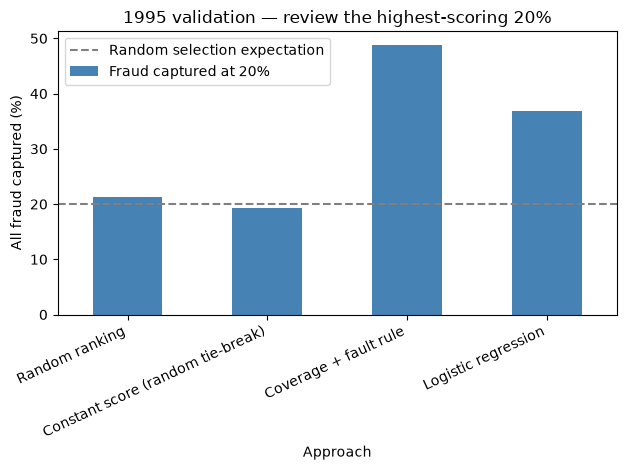

In [58]:
def review_metrics(name, scores):
    review = pd.DataFrame({'Actual fraud': y_val.to_numpy(), 'Score': scores})
    review = review.sample(frac=1, random_state=42)
    review = review.sort_values('Score', ascending=False, kind='stable')
    top_10 = review.head(int(np.ceil(len(review) * 0.10)))
    top_20 = review.head(int(np.ceil(len(review) * 0.20)))
    return {
        'Approach': name,
        'AP': average_precision_score(y_val, scores),
        'Fraud captured at 10%': top_10['Actual fraud'].sum() / y_val.sum(),
        'Fraud captured at 20%': top_20['Actual fraud'].sum() / y_val.sum(),
        'Precision among top 20%': top_20['Actual fraud'].mean(),
        'F1 at 20%': 2 * top_20['Actual fraud'].sum() / (len(top_20) + y_val.sum()),
        'Fraud caught': int(top_20['Actual fraud'].sum()),
        'Claims reviewed': len(top_20)
    }

random_scores = np.random.default_rng(42).random(len(y_val))
constant_scores = np.zeros(len(y_val))
scores_by_approach = {
    'Random ranking': random_scores,
    'Constant score (random tie-break)': constant_scores,
    'Coverage + fault rule': lookup_scores,
    'Logistic regression': val_probabilities
}
results = pd.DataFrame([
    review_metrics(name, scores) for name, scores in scores_by_approach.items()
]).set_index('Approach')
display(results.round(4))
print('Validation fraud prevalence:', round(y_val.mean(), 4))
print('Random-ranking expected fraud capture: about 10% at 10% review, 20% at 20% review.')
print('Claims reviewed at 20%:', int(np.ceil(len(y_val) * 0.20)))

(results['Fraud captured at 20%'] * 100).plot(kind='bar', color='steelblue')
plt.axhline(20, color='gray', linestyle='--', label='Random selection expectation')
plt.ylabel('All fraud captured (%)')
plt.title('1995 validation — review the highest-scoring 20%')
plt.xticks(rotation=25, ha='right')
plt.legend()
plt.tight_layout()
plt.show()


# Classification Metrics and Confusion Matrix

,Approach,Accuracy,Precision,Recall,F1
0,Always non-fraud,0.9421,0.0000,0.0000,0.0000
1,Logistic regression at 0.5,0.7353,0.1016,0.4551,0.1662


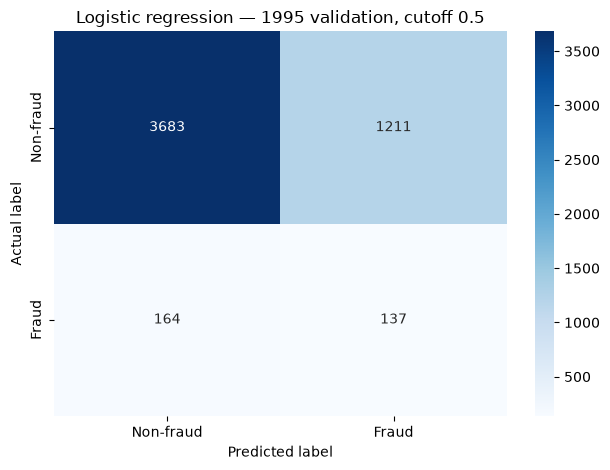

Correct non-fraud: 3683 | False alarms: 1211
Missed fraud: 164 | Fraud caught: 137


In [59]:
val_predictions = (val_probabilities >= 0.5).astype(int)
never_fraud = np.zeros(len(y_val), dtype=int)
classification_results = pd.DataFrame({
    'Approach': ['Always non-fraud', 'Logistic regression at 0.5'],
    'Accuracy': [accuracy_score(y_val, never_fraud), accuracy_score(y_val, val_predictions)],
    'Precision': [0.0, precision_score(y_val, val_predictions, zero_division=0)],
    'Recall': [0.0, recall_score(y_val, val_predictions, zero_division=0)],
    'F1': [0.0, f1_score(y_val, val_predictions, zero_division=0)]
})
display(classification_results.round(4))
matrix = confusion_matrix(y_val, val_predictions, labels=[0, 1])
sns.heatmap(matrix, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Non-fraud', 'Fraud'], yticklabels=['Non-fraud', 'Fraud'])
plt.xlabel('Predicted label')
plt.ylabel('Actual label')
plt.title('Logistic regression — 1995 validation, cutoff 0.5')
plt.tight_layout()
plt.show()
tn, fp, fn, tp = matrix.ravel()
print('Correct non-fraud:', tn, '| False alarms:', fp)
print('Missed fraud:', fn, '| Fraud caught:', tp)


# Check the effect of Fault

In [60]:
fault_columns = [column for column in X_train_ready.columns if column.startswith('Fault_')]
assert len(fault_columns) > 0
model_without_fault = LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)
model_without_fault.fit(X_train_ready.drop(columns=fault_columns), y_train)
no_fault_scores = model_without_fault.predict_proba(X_val_ready.drop(columns=fault_columns))[:, 1]
fault_comparison = pd.DataFrame([
    review_metrics('Logistic regression with Fault', val_probabilities),
    review_metrics('Logistic regression without Fault', no_fault_scores)
]).set_index('Approach')
display(fault_comparison.round(4))


,AP,Fraud captured at 10%,Fraud captured at 20%,Precision among top 20%,F1 at 20%,Fraud caught,Claims reviewed
Approach,,,,,,,
Logistic regression with Fault,0.0968,0.1827,0.3688,0.1068,0.1657,111,1039
Logistic regression without Fault,0.0701,0.1196,0.2392,0.0693,0.1075,72,1039


In [19]:
%pip install shap

Note: you may need to restart the kernel to use updated packages.


# Selection MD: Review the Riskiest 20%

In [61]:

'''selection_note = f"""# Baseline Model Selection

Selected approach: {selected_name}

We compared logistic regression with the coverage + fault rule using
1995 data. We chose the approach that found the most fraud when reviewing
the highest-scoring 20% of claims. If they tied, we used the higher AP score.

## Validation Results
- AP: {selected['AP']:.4f}
- Fraud found when reviewing 10% of claims: {selected['Fraud captured at 10%']:.2%}
- Fraud found when reviewing 20% of claims: {selected['Fraud captured at 20%']:.2%}
- Percentage of reviewed claims that were fraud: {selected['Precision among top 20%']:.2%}

## Next Steps
All training used 1994 data. We still need to confirm whether Fault
is known when a claim is first filed.

We previously looked at 1996 results, but this comparison uses only 1995.
We will finalize our choices before running the final evaluation on 1996.
"""

print(selection_note)'''

'selection_note = f"""# Baseline Model Selection\n\nSelected approach: {selected_name}\n\nWe compared logistic regression with the coverage + fault rule using\n1995 data. We chose the approach that found the most fraud when reviewing\nthe highest-scoring 20% of claims. If they tied, we used the higher AP score.\n\n## Validation Results\n- AP: {selected[\'AP\']:.4f}\n- Fraud found when reviewing 10% of claims: {selected[\'Fraud captured at 10%\']:.2%}\n- Fraud found when reviewing 20% of claims: {selected[\'Fraud captured at 20%\']:.2%}\n- Percentage of reviewed claims that were fraud: {selected[\'Precision among top 20%\']:.2%}\n\n## Next Steps\nAll training used 1994 data. We still need to confirm whether Fault\nis known when a claim is first filed.\n\nWe previously looked at 1996 results, but this comparison uses only 1995.\nWe will finalize our choices before running the final evaluation on 1996.\n"""\n\nprint(selection_note)'

# Part 2: Feature Engineering and Imbalance Handling

In [21]:
import sklearn
import imblearn
from imblearn.over_sampling import SMOTENC
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.utils.class_weight import compute_sample_weight

print('Training claims:', len(y_train), '| Validation claims:', len(y_val))
print('Training fraud rate:', round(y_train.mean(), 4))
print('Validation fraud rate:', round(y_val.mean(), 4))



Training claims: 6141 | Validation claims: 5195
Training fraud rate: 0.0666
Validation fraud rate: 0.0579


# Adding 3 features


| New feature | How it is made | Why try it? |
|---|---|---|
| CoverageFault | Combine BasePolicy and Fault into one category | Lets logistic regression learn a separate effect for each combination, similar to the successful lookup rule. It does not use any fraud labels. |
| HasPriorClaims | 1 when PastNumberOfClaims is above its `none` code, otherwise 0 | Separates having any claim history from having none. |
| WeekendAccident | 1 for Saturday/Sunday, otherwise 0 | Tests a simple weekend pattern without calculating uncertain accident to filing delays. |

In [22]:
def add_features(data):
    engineered = data.copy()
    engineered['CoverageFault'] = engineered['BasePolicy'].astype(str) + ' | ' + engineered['Fault'].astype(str)
    engineered['HasPriorClaims'] = (engineered['PastNumberOfClaims'] > 0).astype(int)
    engineered['WeekendAccident'] = engineered['DayOfWeek'].isin(['Saturday', 'Sunday']).astype(int)
    return engineered

# X_train and X_val already contain Part 1's ages, grouped makes, and range codes.
X_train_fe = add_features(X_train)
X_val_fe = add_features(X_val)
display(X_train_fe[['BasePolicy', 'Fault', 'CoverageFault', 'HasPriorClaims', 'WeekendAccident']].head())


,BasePolicy,Fault,CoverageFault,HasPriorClaims,WeekendAccident
0,Liability,Policy Holder,Liability | Policy Holder,0,0
1,Collision,Policy Holder,Collision | Policy Holder,0,0
2,Collision,Policy Holder,Collision | Policy Holder,1,0
3,Liability,Third Party,Liability | Third Party,1,1
4,Collision,Third Party,Collision | Third Party,0,0


# Encode and scale using training data only
The training columns and scaler are fitted once on the original 1994 rows

In [23]:
fe_category_columns = category_columns + ['CoverageFault']
X_train_fe_encoded = pd.get_dummies(X_train_fe, columns=fe_category_columns, dtype=int)
X_val_fe_encoded = pd.get_dummies(X_val_fe, columns=fe_category_columns, dtype=int)
X_val_fe_encoded = X_val_fe_encoded.reindex(columns=X_train_fe_encoded.columns, fill_value=0)

fe_scaler = StandardScaler()
X_train_fe_scaled = X_train_fe_encoded.copy()
X_val_fe_scaled = X_val_fe_encoded.copy()
X_train_fe_scaled[numeric_columns] = fe_scaler.fit_transform(X_train_fe_encoded[numeric_columns])
X_val_fe_scaled[numeric_columns] = fe_scaler.transform(X_val_fe_encoded[numeric_columns])

assert X_train_fe_encoded.columns.equals(X_val_fe_encoded.columns)
assert not X_train_fe_encoded.isna().any().any()
assert not X_val_fe_encoded.isna().any().any()
print('Engineered input columns after encoding:', X_train_fe_encoded.shape[1])


Engineered input columns after encoding: 97


# Compare three ways to handle imbalance

1. None: keep the original training distribution and use no weights.
2. Balanced weights: give fraud cases more influence without adding rows. Logistic regression and random forest use class_weight and gradient boosting uses equivalent training sample_weight values.
3. SMOTENC: generate extra minority class training examples. This is the mixed data SMOTE variant, so discrete categories remain categories rather than fractional one hot values.

In [26]:
smote_input = X_train.copy()
smote_age_scaler = StandardScaler()
smote_input[['Age']] = smote_age_scaler.fit_transform(X_train[['Age']])
smote_categories = [column for column in smote_input.columns if column != 'Age']

smote = SMOTENC(categorical_features=smote_categories,
                sampling_strategy=0.5, k_neighbors=5, random_state=42)
X_train_resampled, y_train_resampled = smote.fit_resample(smote_input, y_train)
X_train_resampled['Age'] = smote_age_scaler.inverse_transform(X_train_resampled[['Age']]).ravel()
X_train_resampled.loc[X_train_resampled['AgeMissing'] == 1, 'Age'] = training_median

# Obtain consistent new features only after generating the synthetic base rows.
X_train_smote_fe = add_features(X_train_resampled)
X_train_smote_encoded = pd.get_dummies(X_train_smote_fe, columns=fe_category_columns, dtype=int)
X_train_smote_encoded = X_train_smote_encoded.reindex(columns=X_train_fe_encoded.columns, fill_value=0)
X_train_smote_scaled = X_train_smote_encoded.copy()
X_train_smote_scaled[numeric_columns] = fe_scaler.transform(X_train_smote_encoded[numeric_columns])

# SMOTENC must preserve the recorded choices for all categorical inputs.
for column in smote_categories:
    assert set(X_train_resampled[column]).issubset(set(X_train[column]))
assert not X_train_smote_scaled.isna().any().any()
assert len(X_val_fe_encoded) == len(y_val)
display(pd.DataFrame({
    'Original 1994': y_train.value_counts(),
    'After SMOTENC': pd.Series(y_train_resampled).value_counts()
}).rename_axis('FraudFound_P'))


,Original 1994,After SMOTENC
FraudFound_P,,
0,5732,5732
1,409,2866


# Small Tuning Plan
| Model | Two settings | Other settings kept fixed |
|---|---|---|
| Logistic regression | C = 0.1 or 1.0 | max_iter = 1000; smaller C means stronger regularization |
| Random forest | max_depth = 6 or 12 | 200 trees; at least 10 training examples in each leaf |
| Gradient boosting | max_depth = 1 or 2 | 100 trees; learning_rate = 0.05; at least 10 examples per leaf |

In [62]:
experiment_rows = []
experiment_models = {}
experiment_scores = {}

for family in ['Logistic regression', 'Random forest', 'Gradient boosting']:
    settings = [0.1, 1.0] if family == 'Logistic regression' else ([6, 12] if family == 'Random forest' else [1, 2])
    for setting in settings:
        for method in ['None', 'Balanced weights', 'SMOTENC']:
            use_smote = method == 'SMOTENC'
            fit_y = y_train_resampled if use_smote else y_train
            if family == 'Logistic regression':
                fit_X = X_train_smote_scaled if use_smote else X_train_fe_scaled
                eval_X = X_val_fe_scaled
                estimator = LogisticRegression(C=setting, max_iter=1000, random_state=42,
                    class_weight='balanced' if method == 'Balanced weights' else None)
                setting_label = 'C=' + str(setting)
            elif family == 'Random forest':
                fit_X = X_train_smote_encoded if use_smote else X_train_fe_encoded
                eval_X = X_val_fe_encoded
                estimator = RandomForestClassifier(n_estimators=200, max_depth=setting,
                    min_samples_leaf=10, random_state=42, n_jobs=-1,
                    class_weight='balanced' if method == 'Balanced weights' else None)
                setting_label = 'depth=' + str(setting)
            else:
                fit_X = X_train_smote_encoded if use_smote else X_train_fe_encoded
                eval_X = X_val_fe_encoded
                estimator = GradientBoostingClassifier(n_estimators=100, learning_rate=0.05,
                    max_depth=setting, min_samples_leaf=10, random_state=42)
                setting_label = 'depth=' + str(setting)

            # GradientBoostingClassifier uses sample weights rather than class_weight.
            if family == 'Gradient boosting' and method == 'Balanced weights':
                weights = compute_sample_weight(class_weight='balanced', y=y_train)
                estimator.fit(fit_X, fit_y, sample_weight=weights)
            else:
                estimator.fit(fit_X, fit_y)

            run_name = family + ' | ' + setting_label + ' | ' + method
            scores = estimator.predict_proba(eval_X)[:, 1]
            predicted = (scores >= 0.5).astype(int)
            row = review_metrics(run_name, scores)
            row.update({
                'Family': family, 'Setting': setting_label, 'Imbalance method': method,
                'Training rows': len(fit_y),
                'Accuracy at 0.5': accuracy_score(y_val, predicted),
                'Precision at 0.5': precision_score(y_val, predicted, zero_division=0),
                'Recall at 0.5': recall_score(y_val, predicted, zero_division=0),
                'F1 at 0.5': f1_score(y_val, predicted, zero_division=0)
            })
            experiment_rows.append(row)
            experiment_models[run_name] = estimator
            experiment_scores[run_name] = scores
            print('Completed:', run_name)

experiments = pd.DataFrame(experiment_rows).set_index('Approach')
experiments = experiments.sort_values(['Fraud captured at 20%', 'AP'], ascending=False)
assert len(experiments) == 18
display(experiments.round(4))


Completed: Logistic regression | C=0.1 | None
Completed: Logistic regression | C=0.1 | Balanced weights
Completed: Logistic regression | C=0.1 | SMOTENC
Completed: Logistic regression | C=1.0 | None
Completed: Logistic regression | C=1.0 | Balanced weights
Completed: Logistic regression | C=1.0 | SMOTENC
Completed: Random forest | depth=6 | None
Completed: Random forest | depth=6 | Balanced weights
Completed: Random forest | depth=6 | SMOTENC
Completed: Random forest | depth=12 | None
Completed: Random forest | depth=12 | Balanced weights
Completed: Random forest | depth=12 | SMOTENC
Completed: Gradient boosting | depth=1 | None
Completed: Gradient boosting | depth=1 | Balanced weights
Completed: Gradient boosting | depth=1 | SMOTENC
Completed: Gradient boosting | depth=2 | None
Completed: Gradient boosting | depth=2 | Balanced weights
Completed: Gradient boosting | depth=2 | SMOTENC


,AP,Fraud captured at 10%,Fraud captured at 20%,Precision among top 20%,F1 at 20%,Fraud caught,Claims reviewed,Family,Setting,Imbalance method,Training rows,Accuracy at 0.5,Precision at 0.5,Recall at 0.5,F1 at 0.5
Approach,,,,,,,,,,,,,,,
Random forest | depth=6 | None,0.1182,0.2060,0.5050,0.1463,0.2269,152,1039,Random forest,depth=6,None,6141,0.9421,0.0000,0.0000,0.0000
Gradient boosting | depth=1 | None,0.1176,0.1860,0.4751,0.1376,0.2134,143,1039,Gradient boosting,depth=1,None,6141,0.9421,0.0000,0.0000,0.0000
Random forest | depth=12 | None,0.1172,0.1927,0.4551,0.1319,0.2045,137,1039,Random forest,depth=12,None,6141,0.9421,0.0000,0.0000,0.0000
Gradient boosting | depth=1 | SMOTENC,0.1252,0.2226,0.4419,0.1280,0.1985,133,1039,Gradient boosting,depth=1,SMOTENC,8598,0.8568,0.1351,0.2724,0.1806
Gradient boosting | depth=1 | Balanced weights,0.1129,0.1894,0.4319,0.1251,0.1940,130,1039,Gradient boosting,depth=1,Balanced weights,6141,0.6635,0.1202,0.7608,0.2076
Random forest | depth=12 | Balanced weights,0.1093,0.1794,0.4086,0.1184,0.1836,123,1039,Random forest,depth=12,Balanced weights,6141,0.7176,0.1092,0.5415,0.1818
Random forest | depth=6 | SMOTENC,0.1134,0.2159,0.4053,0.1174,0.1821,122,1039,Random forest,depth=6,SMOTENC,8598,0.8656,0.1276,0.2259,0.1631
Gradient boosting | depth=2 | None,0.1093,0.1860,0.3987,0.1155,0.1791,120,1039,Gradient boosting,depth=2,None,6141,0.9421,0.0000,0.0000,0.0000
Random forest | depth=6 | Balanced weights,0.1090,0.1794,0.3987,0.1155,0.1791,120,1039,Random forest,depth=6,Balanced weights,6141,0.6803,0.1096,0.6346,0.1870


# Comparing if Feature Engineering Helped Logistic Regression


In [63]:
engineered_lr_name = 'Logistic regression | C=1.0 | Balanced weights'
feature_comparison = pd.DataFrame([
    review_metrics('Original logistic regression', val_probabilities),
    review_metrics('Logistic regression + three features', experiment_scores[engineered_lr_name])
]).set_index('Approach')
display(feature_comparison.round(4))


,AP,Fraud captured at 10%,Fraud captured at 20%,Precision among top 20%,F1 at 20%,Fraud caught,Claims reviewed
Approach,,,,,,,
Original logistic regression,0.0968,0.1827,0.3688,0.1068,0.1657,111,1039
Logistic regression + three features,0.0982,0.1927,0.3754,0.1088,0.1687,113,1039


# Comparing Strongest Candidate from Random Forest, Gradient Boosting, and Logistic Regression

,Family,Setting,Imbalance method,AP,Fraud captured at 10%,Fraud captured at 20%,Precision among top 20%
Approach,,,,,,,
Random forest | depth=6 | None,Random forest,depth=6,None,0.1182,0.2060,0.5050,0.1463
Gradient boosting | depth=1 | None,Gradient boosting,depth=1,None,0.1176,0.1860,0.4751,0.1376
Logistic regression | C=1.0 | SMOTENC,Logistic regression,C=1.0,SMOTENC,0.0944,0.1628,0.3787,0.1097


,AP,Fraud captured at 10%,Fraud captured at 20%,Precision among top 20%,F1 at 20%,Fraud caught,Claims reviewed
Approach,,,,,,,
Random ranking (reference),0.0651,0.0963,0.2126,0.0616,0.0955,64,1039
Constant score (random tie-break),0.0579,0.1130,0.1927,0.0558,0.0866,58,1039
Coverage + fault rule,0.1289,0.2392,0.4884,0.1415,0.2194,147,1039
Original logistic regression,0.0968,0.1827,0.3688,0.1068,0.1657,111,1039
Random forest | depth=6 | None,0.1182,0.2060,0.5050,0.1463,0.2269,152,1039
Gradient boosting | depth=1 | None,0.1176,0.1860,0.4751,0.1376,0.2134,143,1039
Logistic regression | C=1.0 | SMOTENC,0.0944,0.1628,0.3787,0.1097,0.1701,114,1039


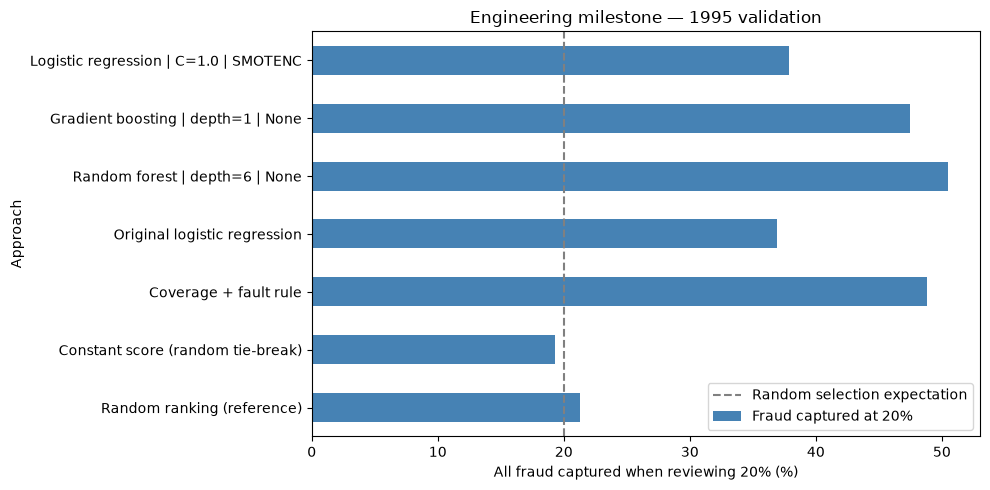

In [64]:
best_by_family = experiments.drop_duplicates(subset='Family', keep='first')
display(best_by_family[['Family', 'Setting', 'Imbalance method', 'AP',
                        'Fraud captured at 10%', 'Fraud captured at 20%',
                        'Precision among top 20%']].round(4))

comparison_rows = [
    review_metrics('Random ranking (reference)', random_scores),
    review_metrics('Constant score (random tie-break)', constant_scores),
    review_metrics('Coverage + fault rule', lookup_scores),
    review_metrics('Original logistic regression', val_probabilities)
]
for run_name in best_by_family.index:
    comparison_rows.append(review_metrics(run_name, experiment_scores[run_name]))
engineering_comparison = pd.DataFrame(comparison_rows).set_index('Approach')
display(engineering_comparison.round(4))

(engineering_comparison['Fraud captured at 20%'] * 100).plot(kind='barh', figsize=(10, 5), color='steelblue')
plt.axvline(20, color='gray', linestyle='--', label='Random selection expectation')
plt.xlabel('All fraud captured when reviewing 20% (%)')
plt.title('Engineering milestone — 1995 validation')
plt.legend()
plt.tight_layout()
plt.show()


# Updated Selection

In [65]:
best_new_name = experiments.index[0]
selection_candidates = engineering_comparison.loc[
    ['Coverage + fault rule', 'Original logistic regression', best_new_name]
].sort_values(['Fraud captured at 20%', 'AP'], ascending=False)
engineering_selected_name = selection_candidates.index[0]
engineering_selected_metrics = selection_candidates.iloc[0]
print('Best new model:', best_new_name)
print('Selected overall approach:', engineering_selected_name)
display(selection_candidates.round(4))

if engineering_selected_name == 'Coverage + fault rule':
    engineering_selected_scores = lookup_scores
elif engineering_selected_name == 'Original logistic regression':
    engineering_selected_scores = val_probabilities
else:
    engineering_selected_scores = experiment_scores[engineering_selected_name]

ranked = pd.DataFrame({'Actual fraud': y_val.to_numpy(), 'Score': engineering_selected_scores})
ranked = ranked.sample(frac=1, random_state=42).sort_values('Score', ascending=False, kind='stable')
review_count = int(np.ceil(len(ranked) * 0.20))
reviewed = ranked.head(review_count)
caught = int(reviewed['Actual fraud'].sum())
print('Claims reviewed:', review_count)
print('Fraud caught:', caught, 'out of', int(y_val.sum()))
print('Non-fraud claims reviewed:', review_count - caught)
print('Fraud missed:', int(y_val.sum()) - caught)

Best new model: Random forest | depth=6 | None
Selected overall approach: Random forest | depth=6 | None


,AP,Fraud captured at 10%,Fraud captured at 20%,Precision among top 20%,F1 at 20%,Fraud caught,Claims reviewed
Approach,,,,,,,
Random forest | depth=6 | None,0.1182,0.2060,0.5050,0.1463,0.2269,152,1039
Coverage + fault rule,0.1289,0.2392,0.4884,0.1415,0.2194,147,1039
Original logistic regression,0.0968,0.1827,0.3688,0.1068,0.1657,111,1039


Claims reviewed: 1039
Fraud caught: 152 out of 301
Non-fraud claims reviewed: 887
Fraud missed: 149


### comparing amongst different categories

In [31]:
from sklearn.metrics import roc_auc_score

# 1) The three things we compare, all scored on 1995 in val_df order
models = {
    'Coverage + fault rule': lookup_scores,
    'Original logistic regression': val_probabilities,
    'Best new model (' + best_new_name + ')': experiment_scores[best_new_name],
}

y = y_val.to_numpy()
group_label = (val_df['BasePolicy'] + ' | ' + val_df['Fault']).to_numpy()   # one label per 1995 claim
group_names = sorted(set(group_label)) + ['ALL CLAIMS']                      # last row = sanity check

# 2) One global review queue: top 20% of ALL 1995 claims, same tie-break as review_metrics
review_n = int(np.ceil(len(y) * 0.20))
perm = np.random.default_rng(42).permutation(len(y))

rows = []
for model_name, scores in models.items():
    scores = np.asarray(scores)
    order = perm[np.argsort(-scores[perm], kind='stable')]   # shuffle, then stable sort high -> low
    flagged = np.zeros(len(y), dtype=bool)
    flagged[order[:review_n]] = True                          # True = claim is in the review queue

    # 3) Slice that same queue by group
    for g in group_names:
        in_group = np.ones(len(y), dtype=bool) if g == 'ALL CLAIMS' else (group_label == g)
        n_claims = int(in_group.sum())
        n_fraud = int(y[in_group].sum())
        n_flagged = int((flagged & in_group).sum())
        n_caught = int((flagged & in_group & (y == 1)).sum())
        rows.append({
            'Group': g, 'Model': model_name,
            'Claims': n_claims, 'Fraud': n_fraud,
            'Flagged': n_flagged, 'Fraud caught': n_caught,
            '% of group fraud caught': round(100 * n_caught / n_fraud, 1) if n_fraud else np.nan,
            'Precision of flagged': round(100 * n_caught / n_flagged, 1) if n_flagged else np.nan,
            # ranking quality inside the group (ignores the budget)
            'AP in group': round(average_precision_score(y[in_group], scores[in_group]), 4) if n_fraud else np.nan,
            'ROC-AUC in group': round(roc_auc_score(y[in_group], scores[in_group]), 3) if 0 < n_fraud < n_claims else np.nan,
        })

group_report = pd.DataFrame(rows).set_index(['Group', 'Model'])
display(group_report)
print('Claims in the review queue (20%):', review_n)

,,Claims,Fraud,Flagged,Fraud caught,% of group fraud caught,Precision of flagged,AP in group,ROC-AUC in group
Group,Model,,,,,,,,
All Perils | Policy Holder,Coverage + fault rule,940,138,940,138,100.0,14.7,0.1468,0.500
All Perils | Third Party,Coverage + fault rule,561,7,0,0,0.0,NaN,0.0125,0.500
Collision | Policy Holder,Coverage + fault rule,1353,139,99,10,7.2,10.1,0.1027,0.500
Collision | Third Party,Coverage + fault rule,589,6,0,0,0.0,NaN,0.0102,0.500
Liability | Policy Holder,Coverage + fault rule,1482,11,0,0,0.0,NaN,0.0074,0.500
Liability | Third Party,Coverage + fault rule,270,0,0,0,NaN,NaN,NaN,NaN
ALL CLAIMS,Coverage + fault rule,5195,301,1039,148,49.2,14.2,0.1289,0.775
All Perils | Policy Holder,Original logistic regression,940,138,571,65,47.1,11.4,0.1159,0.379
All Perils | Third Party,Original logistic regression,561,7,5,0,0.0,0.0,0.0138,0.514


Claims in the review queue (20%): 1039


# Part 3 — Final evaluation

In [34]:
print('Final model: Random forest')
print('Settings: 200 trees, maximum depth 6, minimum samples per leaf 10')
print('Class weights: None | Random seed: 42')
print('Review rule: highest-scoring 20% of claims')
print('Original features:', kept_columns)
print('Added features: AgeMissing, CoverageFault, HasPriorClaims, WeekendAccident')
print('Dropped features:', list(drop_reasons))




Final model: Random forest
Settings: 200 trees, maximum depth 6, minimum samples per leaf 10
Class weights: None | Random seed: 42
Review rule: highest-scoring 20% of claims
Original features: ['Month', 'WeekOfMonth', 'DayOfWeek', 'Make', 'AccidentArea', 'DayOfWeekClaimed', 'MonthClaimed', 'WeekOfMonthClaimed', 'Sex', 'MaritalStatus', 'Age', 'Fault', 'VehicleCategory', 'VehiclePrice', 'Deductible', 'DriverRating', 'Days_Policy_Accident', 'Days_Policy_Claim', 'PastNumberOfClaims', 'AgeOfVehicle', 'AgeOfPolicyHolder', 'AgentType', 'NumberOfCars', 'BasePolicy']
Added features: AgeMissing, CoverageFault, HasPriorClaims, WeekendAccident
Dropped features: ['PolicyNumber', 'RepNumber', 'PolicyType', 'PoliceReportFiled', 'WitnessPresent', 'NumberOfSuppliments', 'AddressChange_Claim', 'Year']


# Prepare the final training and test data

In [36]:
final_train_raw = df[df['Year'].isin([1994, 1995])].copy()
final_test_raw = df[df['Year'] == 1996].copy()

final_X_train = final_train_raw[kept_columns].copy()
final_X_test = final_test_raw[kept_columns].copy()
final_y_train = final_train_raw['FraudFound_P'].copy()
final_y_test = final_test_raw['FraudFound_P'].copy()

# Learn these values from the combined training years only.
final_age_median = final_X_train['Age'].replace(0, np.nan).median()
make_counts = final_X_train['Make'].value_counts()
final_common_makes = make_counts[make_counts >= 50].index

for data in [final_X_train, final_X_test]:
    data['AgeMissing'] = ((data['Age'] == 0) | data['Age'].isna()).astype(int)
    data['Age'] = data['Age'].replace(0, np.nan).fillna(final_age_median)
    data['Make'] = data['Make'].where(data['Make'].isin(final_common_makes), 'Other')
    for column, mapping in range_codes.items():
        data[column] = data[column].map(mapping)
        assert data[column].notna().all(), 'Unrecognized category: ' + column

# Reuse the feature engineering function from Part 2.
final_train_features = add_features(final_X_train)
final_test_features = add_features(final_X_test)

final_X_train = pd.get_dummies(final_train_features, columns=fe_category_columns, dtype=int)
final_X_test = pd.get_dummies(final_test_features, columns=fe_category_columns, dtype=int)
final_X_test = final_X_test.reindex(columns=final_X_train.columns, fill_value=0)

assert not final_X_train.isna().any().any()
assert not final_X_test.isna().any().any()
assert set(final_X_train.index).isdisjoint(final_X_test.index)
print('Training claims:', len(final_X_train))
print('Test claims:', len(final_X_test))
print('Training age median:', final_age_median)


Training claims: 11336
Test claims: 4083
Training age median: 38.0


# Train the model and score 1996

In [66]:
from sklearn.ensemble import RandomForestClassifier

def capacity_results(actual, scores):
    ranked = pd.DataFrame({'Actual': np.asarray(actual), 'Score': scores})
    ranked = ranked.sample(frac=1, random_state=42).sort_values('Score', ascending=False, kind='stable')
    count = int(np.ceil(len(ranked) * 0.20))
    flags = np.zeros(len(ranked), dtype=int)
    flags[ranked.head(count).index] = 1
    caught = int(np.asarray(actual)[flags == 1].sum())
    metrics = {'AP': average_precision_score(actual, scores),
               'Fraud captured at 20%': recall_score(actual, flags),
               'Precision among top 20%': precision_score(actual, flags, zero_division=0),
               'F1 at 20%': f1_score(actual, flags),
               'Accuracy at 20%': accuracy_score(actual, flags),
               'Claims reviewed': count, 'Fraud caught': caught,
               'Honest claims flagged': count - caught,
               'Fraud missed': int(np.asarray(actual).sum()) - caught}
    return metrics, flags

# Define the model directly in this cell.
final_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=6,
    min_samples_leaf=10,
    class_weight=None,
    random_state=42,
    n_jobs=-1
)
final_model.fit(final_X_train, final_y_train)
final_scores = final_model.predict_proba(final_X_test)[:, 1]
final_metrics, final_flags = capacity_results(final_y_test, final_scores)
headline = f"Reviewing the top 20% of claims catches {final_metrics['Fraud captured at 20%']:.2%} of fraud, compared with 20% if we picked claims at random."
print(headline)
display(pd.DataFrame([final_metrics], index=['1996 final test']).round(4))
display(pd.DataFrame(confusion_matrix(final_y_test, final_flags),
                     index=['Actually honest', 'Actually fraud'], columns=['Not reviewed', 'Reviewed']))
yearly_rates = df.groupby('Year')['FraudFound_P'].agg(['size', 'sum', 'mean'])
display(yearly_rates.rename(columns={'size':'Claims', 'sum':'Fraud cases', 'mean':'Fraud rate'}))
validation_capture = experiments.loc['Random forest | depth=6 | None', 'Fraud captured at 20%']
print('1995 validation capture:', f"{validation_capture:.2%}")
print('1996 final capture:', f"{final_metrics['Fraud captured at 20%']:.2%}")
if final_metrics['Fraud captured at 20%'] < validation_capture / 2:
    print('Large drop: inspect data alignment and preprocessing for bugs. Do not tune to improve this test score.')


Reviewing the top 20% of claims catches 40.38% of fraud, compared with 20% if we picked claims at random.


,AP,Fraud captured at 20%,Precision among top 20%,F1 at 20%,Accuracy at 20%,Claims reviewed,Fraud caught,Honest claims flagged,Fraud missed
1996 final test,0.1057,0.4038,0.1053,0.167,0.7899,817,86,731,127


,Not reviewed,Reviewed
Actually honest,3139,731
Actually fraud,127,86


,Claims,Fraud cases,Fraud rate
Year,,,
1994,6141,409,0.066602
1995,5195,301,0.057940
1996,4083,213,0.052168


1995 validation capture: 50.50%
1996 final capture: 40.38%


# Compare Random Forest and the Lookup Rule on 1996

In [67]:
final_lookup_rates = final_train_raw.groupby(['BasePolicy', 'Fault'])['FraudFound_P'].mean()
lookup_dictionary = final_lookup_rates.to_dict()
final_lookup_scores = np.array([
    lookup_dictionary.get((coverage, fault), final_y_train.mean())
    for coverage, fault in zip(final_test_raw['BasePolicy'], final_test_raw['Fault'])
])
lookup_metrics_1996, lookup_flags_1996 = capacity_results(final_y_test, final_lookup_scores)
comparison_1996 = pd.DataFrame([final_metrics, lookup_metrics_1996],
                              index=['Random Forest', 'Coverage + fault rule'])
display(comparison_1996.round(4))
assert final_flags.sum() == lookup_flags_1996.sum() == int(np.ceil(len(final_y_test) * 0.20))

print('Random review expectations at the same capacity:')
print('Recall:', f"{final_flags.sum() / len(final_y_test):.2%}")
print('Precision:', f"{final_y_test.mean():.2%}")
print('Expected fraud caught:', round(final_flags.sum() * final_y_test.mean(), 1))
print('These are expectations, not results from another trained model.')
for name, metrics in comparison_1996.iterrows():
    lift = metrics['Fraud captured at 20%'] / (final_flags.sum() / len(final_y_test))
    print(name + ':', f'{lift:.2f} times the expected fraud capture of random review.')
print('Tied lookup scores can change the exact fraud count at the review boundary.')
print('Keep the seed fixed; do not try seeds until the results improve.')


,AP,Fraud captured at 20%,Precision among top 20%,F1 at 20%,Accuracy at 20%,Claims reviewed,Fraud caught,Honest claims flagged,Fraud missed
Random Forest,0.1057,0.4038,0.1053,0.1670,0.7899,817,86,731,127
Coverage + fault rule,0.1031,0.4131,0.1077,0.1709,0.7908,817,88,729,125


Random review expectations at the same capacity:
Recall: 20.01%
Precision: 5.22%
Expected fraud caught: 42.6
These are expectations, not results from another trained model.
Random Forest: 2.02 times the expected fraud capture of random review.
Coverage + fault rule: 2.06 times the expected fraud capture of random review.
Tied lookup scores can change the exact fraud count at the review boundary.
Keep the seed fixed; do not try seeds until the results improve.


# Compare the Mistakes Between Random Forest and Lookup Rule

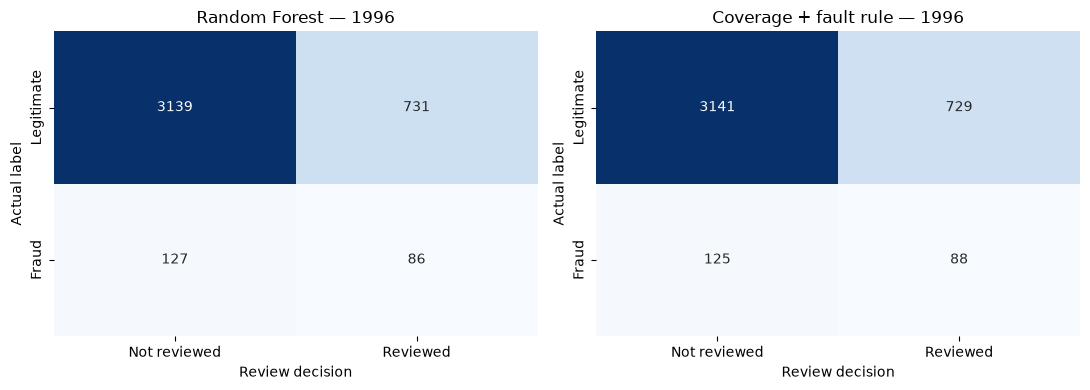

In [68]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, name, flags in zip(axes, ['Random Forest', 'Coverage + fault rule'],
                          [final_flags, lookup_flags_1996]):
    matrix = confusion_matrix(final_y_test, flags, labels=[0, 1])
    sns.heatmap(matrix, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax,
                xticklabels=['Not reviewed', 'Reviewed'],
                yticklabels=['Legitimate', 'Fraud'])
    ax.set_title(name + ' — 1996')
    ax.set_xlabel('Review decision')
    ax.set_ylabel('Actual label')
plt.tight_layout()
plt.show()


# Check Fault and Sex without changing the chosen model

In [69]:
from sklearn.base import clone

# Map dummy columns back to their original or engineered feature.
encoded_groups = {}
for feature in final_train_features.columns:
    columns = [c for c in final_X_train.columns if c.startswith(feature + '_')] if feature in fe_category_columns else [feature]
    for column in columns:
        assert column not in encoded_groups
        encoded_groups[column] = feature
assert set(encoded_groups) == set(final_X_train.columns)

diagnostic_rows = [{'Run': 'Chosen model', **final_metrics}]
for label, removed in [('Without Fault', ['Fault', 'CoverageFault']), ('Without Sex', ['Sex'])]:
    remaining = [c for c in final_X_train if encoded_groups[c] not in removed]
    diagnostic_model = clone(final_model)
    diagnostic_model.fit(final_X_train[remaining], final_y_train)
    diagnostic_scores = diagnostic_model.predict_proba(final_X_test[remaining])[:, 1]
    metrics, _ = capacity_results(final_y_test, diagnostic_scores)
    diagnostic_rows.append({'Run': label, **metrics})
diagnostic_results = pd.DataFrame(diagnostic_rows).set_index('Run')
diagnostic_results['Capture change (percentage points)'] = 100 * (diagnostic_results['Fraud captured at 20%'] - final_metrics['Fraud captured at 20%'])
display(diagnostic_results.round(4))
for label in ['Without Fault', 'Without Sex']:
    print(f"{label}: capture is {diagnostic_results.loc[label, 'Fraud captured at 20%']:.2%}, a change of {diagnostic_results.loc[label, 'Capture change (percentage points)']:+.2f} percentage points. This does not change our selection.")


,AP,Fraud captured at 20%,Precision among top 20%,F1 at 20%,Accuracy at 20%,Claims reviewed,Fraud caught,Honest claims flagged,Fraud missed,Capture change (percentage points)
Run,,,,,,,,,,
Chosen model,0.1057,0.4038,0.1053,0.1670,0.7899,817,86,731,127,0.0000
Without Fault,0.0710,0.2629,0.0685,0.1087,0.7752,817,56,761,157,-14.0845
Without Sex,0.1039,0.4085,0.1065,0.1689,0.7904,817,87,730,126,0.4695


Without Fault: capture is 26.29%, a change of -14.08 percentage points. This does not change our selection.
Without Sex: capture is 40.85%, a change of +0.47 percentage points. This does not change our selection.


# Explain scores with SHAP

,Mean absolute grouped SHAP
Fault,0.018288
CoverageFault,0.017341
BasePolicy,0.013923
VehicleCategory,0.008109
MonthClaimed,0.001672
VehiclePrice,0.001574
AccidentArea,0.001555
Age,0.001484
Month,0.001453
Deductible,0.001254


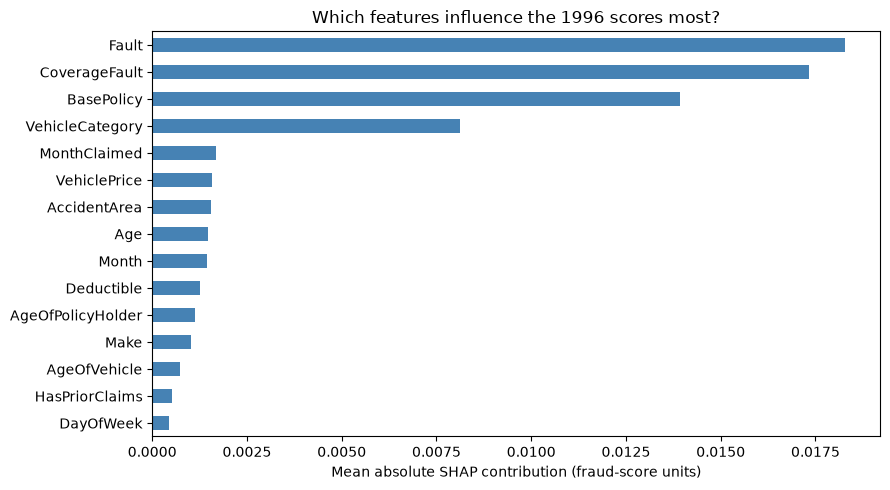

Top features: Fault, CoverageFault, BasePolicy, VehicleCategory, MonthClaimed
Timing features in top five: ['MonthClaimed']
IDs and Year are excluded. Timing importance alone is not proof of leakage.


In [70]:
import shap

explainer = shap.TreeExplainer(final_model, feature_perturbation='tree_path_dependent', model_output='raw')
all_shap_values = explainer.shap_values(final_X_test)
# Select the fraud class (class 1); support both older and newer SHAP output formats.
if isinstance(all_shap_values, list):
    shap_values = np.asarray(all_shap_values[1])
else:
    shap_values = np.asarray(all_shap_values)[:, :, 1]
shap_base = float(np.asarray(explainer.expected_value).reshape(-1)[1])
assert shap_values.shape == final_X_test.shape
assert np.allclose(shap_base + shap_values.sum(axis=1), final_scores)
shap_frame = pd.DataFrame(shap_values, columns=final_X_test.columns, index=final_X_test.index)
grouped_shap = pd.DataFrame(index=final_X_test.index)
for feature in final_train_features.columns:
    columns = [c for c in final_X_test if encoded_groups[c] == feature]
    grouped_shap[feature] = shap_frame[columns].sum(axis=1)
assert np.allclose(grouped_shap.sum(axis=1), shap_frame.sum(axis=1))
global_importance = grouped_shap.abs().mean().sort_values(ascending=False)
display(global_importance.to_frame('Mean absolute grouped SHAP').head(15))
global_importance.head(15).sort_values().plot.barh(figsize=(9, 5), color='steelblue')
plt.xlabel('Mean absolute SHAP contribution (fraud-score units)')
plt.title('Which features influence the 1996 scores most?')
plt.tight_layout()
plt.show()
print('Top features:', ', '.join(global_importance.head(5).index))
time_features = {'Month', 'MonthClaimed', 'WeekOfMonth', 'WeekOfMonthClaimed', 'DayOfWeek', 'DayOfWeekClaimed', 'WeekendAccident'}
print('Timing features in top five:', list(set(global_importance.head(5).index) & time_features))
assert not set(['PolicyNumber', 'RepNumber', 'Year']) & set(final_train_features.columns)
print('IDs and Year are excluded. Timing importance alone is not proof of leakage.')


# Explaination for three real claims


In [42]:
outcome_masks = {
    'Fraud caught': (final_y_test.to_numpy() == 1) & (final_flags == 1),
    'Honest claim flagged': (final_y_test.to_numpy() == 0) & (final_flags == 1),
    'Fraud missed': (final_y_test.to_numpy() == 1) & (final_flags == 0)
}
example_notes = []
for outcome, mask in outcome_masks.items():
    positions = np.flatnonzero(mask)
    if len(positions) == 0:
        print('No example exists for:', outcome)
        continue
    pos = positions[0]
    row_id = final_X_test.index[pos]
    contributions = grouped_shap.loc[row_id]
    strongest = contributions.abs().nlargest(5).index
    detail = pd.DataFrame({'Feature': strongest,
                           'Contribution': contributions[strongest].values})
    detail['Recorded / derived value'] = [str(final_test_raw.loc[row_id, f]) if f in final_test_raw else str(final_test_features.loc[row_id, f]) for f in strongest]
    print(outcome, '| Policy:', final_test_raw.loc[row_id, 'PolicyNumber'], '| Score:', round(final_scores[pos], 4))
    display(detail)
    sentences = []
    for f in strongest:
        value = str(final_test_raw.loc[row_id, f]) if f in final_test_raw else str(final_test_features.loc[row_id, f])
        effect = contributions[f]
        if abs(effect) > 1e-10:
            sentences.append(f'{f} = {value} pushed the score {"up" if effect > 0 else "down"} ({effect * 100:+.2f} percentage points in the model score).')
    decision = 'This claim was in the highest-scoring 20% and was sent for review.' if final_flags[pos] else 'This claim ranked below the review group and was not sent for review.'
    note = f"### {outcome} — policy {final_test_raw.loc[row_id, 'PolicyNumber']}\nScore: {final_scores[pos]:.4f}. {decision}\n" + ' '.join(sentences)
    example_notes.append(note)
    print(note)
    print('These are model explanations, not proof of fraud or innocence.\n')


Fraud caught | Policy: 11415 | Score: 0.153


,Feature,Contribution,Recorded / derived value
0,CoverageFault,0.038103,All Perils | Policy Holder
1,BasePolicy,0.026189,All Perils
2,Fault,0.018734,Policy Holder
3,VehicleCategory,0.009638,Sedan
4,Age,0.002915,36


### Fraud caught — policy 11415
Score: 0.1530. This claim was in the highest-scoring 20% and was sent for review.
CoverageFault = All Perils | Policy Holder pushed the score up (+3.81 percentage points in the model score). BasePolicy = All Perils pushed the score up (+2.62 percentage points in the model score). Fault = Policy Holder pushed the score up (+1.87 percentage points in the model score). VehicleCategory = Sedan pushed the score up (+0.96 percentage points in the model score). Age = 36 pushed the score up (+0.29 percentage points in the model score).
These are model explanations, not proof of fraud or innocence.

Honest claim flagged | Policy: 11338 | Score: 0.1263


,Feature,Contribution,Recorded / derived value
0,CoverageFault,0.033194,All Perils | Policy Holder
1,BasePolicy,0.022743,All Perils
2,Fault,0.017175,Policy Holder
3,VehicleCategory,0.008296,Sedan
4,Age,-0.003597,52


### Honest claim flagged — policy 11338
Score: 0.1263. This claim was in the highest-scoring 20% and was sent for review.
CoverageFault = All Perils | Policy Holder pushed the score up (+3.32 percentage points in the model score). BasePolicy = All Perils pushed the score up (+2.27 percentage points in the model score). Fault = Policy Holder pushed the score up (+1.72 percentage points in the model score). VehicleCategory = Sedan pushed the score up (+0.83 percentage points in the model score). Age = 52 pushed the score down (-0.36 percentage points in the model score).
These are model explanations, not proof of fraud or innocence.

Fraud missed | Policy: 11345 | Score: 0.0859


,Feature,Contribution,Recorded / derived value
0,Fault,0.014224,Policy Holder
1,CoverageFault,0.007373,Collision | Policy Holder
2,VehicleCategory,0.004538,Sedan
3,BasePolicy,0.003642,Collision
4,Month,-0.001412,Apr


### Fraud missed — policy 11345
Score: 0.0859. This claim ranked below the review group and was not sent for review.
Fault = Policy Holder pushed the score up (+1.42 percentage points in the model score). CoverageFault = Collision | Policy Holder pushed the score up (+0.74 percentage points in the model score). VehicleCategory = Sedan pushed the score up (+0.45 percentage points in the model score). BasePolicy = Collision pushed the score up (+0.36 percentage points in the model score). Month = Apr pushed the score down (-0.14 percentage points in the model score).
These are model explanations, not proof of fraud or innocence.



# Model Summary

In [71]:
print('Final model: Random forest with no class weights')
print(headline)
print(f"AP: {final_metrics['AP']:.4f}")
print(f"Precision among reviewed claims: {final_metrics['Precision among top 20%']:.2%}")
print('Fraud caught:', final_metrics['Fraud caught'])
print('Honest claims flagged:', final_metrics['Honest claims flagged'])
print('Fraud missed:', final_metrics['Fraud missed'])
print('Most influential features:', ', '.join(global_importance.head(5).index))
print('Without Fault:', f"{diagnostic_results.loc['Without Fault', 'Fraud captured at 20%']:.2%} fraud capture")
print('Without Sex:', f"{diagnostic_results.loc['Without Sex', 'Fraud captured at 20%']:.2%} fraud capture")


Final model: Random forest with no class weights
Reviewing the top 20% of claims catches 40.38% of fraud, compared with 20% if we picked claims at random.
AP: 0.1057
Precision among reviewed claims: 10.53%
Fraud caught: 86
Honest claims flagged: 731
Fraud missed: 127
Most influential features: Fault, CoverageFault, BasePolicy, VehicleCategory, MonthClaimed
Without Fault: 26.29% fraud capture
Without Sex: 40.85% fraud capture
